In [ ]:
import ast
from collections import Counter
import json
import re
import time
import warnings

from bs4 import BeautifulSoup
import folium
from googlesearch import search
from kiwipiepy import Kiwi
from konlpy.tag import Okt
import matplotlib
from matplotlib import font_manager, rc
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from wordcloud import WordCloud

# 경고 메시지 무시 설정
warnings.filterwarnings(action='ignore')

# 매직 명령어 및 소수점 설정
%precision 3
%matplotlib inline

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
matplotlib.rc('font', family=font_name)

In [2]:
print(pd.__version__)

2.2.3


In [15]:
df = pd.read_csv('./data/card_usage_simple.csv')

In [16]:
df

,day_type,amount_band
0,weekday,mid
1,weekend,low
2,weekday,low
3,weekday,low
4,weekday,low
...,...,...
9995,weekday,mid
9996,weekday,low
9997,weekend,mid
9998,weekday,low


In [5]:
df.value_counts()

day_type  amount_band
weekday   low            4300
          mid            2014
weekend   low            1207
          mid            1022
          high            743
weekday   high            714
Name: count, dtype: int64

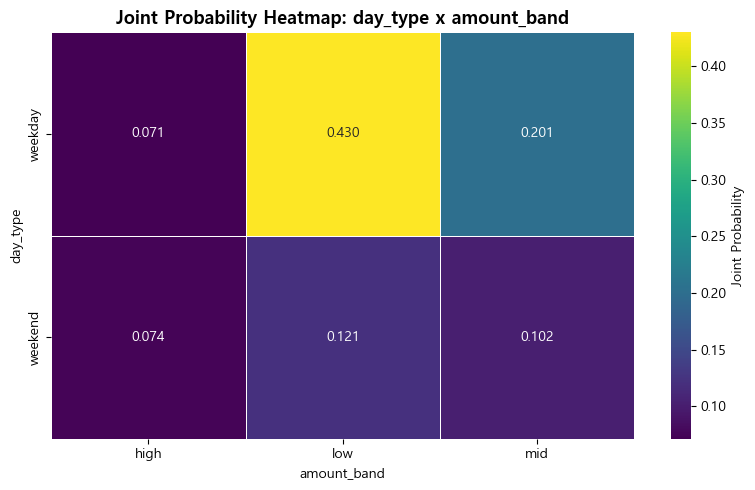

In [44]:
# bins = list(range(0, 110, 10))
# labels = [f'{i}~{i+10}' for i in range(0, 100, 10)]

# df['time_class'] = pd.cut(
#     df['delivery_minutes'], bins=bins, labels=labels, right=False
# )
#어제 썼던 히트맵 재탕 
new_df = pd.crosstab(
    df['day_type'], df['amount_band'], normalize=True
)
cols = ['high', 'low', 'mid']
prob = new_df / new_df.values.sum()
plt.figure(figsize=(8, 5))

sns.heatmap(
    prob,
    annot=True,
    cmap='viridis',
    linewidths=0.5,
    fmt='.3f',
    cbar_kws={"label": "Joint Probability"}
)

plt.title(
    'Joint Probability Heatmap: day_type x amount_band',
    fontsize=13,
    fontweight='bold',
)
plt.ylabel('day_type')
plt.xlabel('amount_band')


plt.tight_layout()
plt.show()

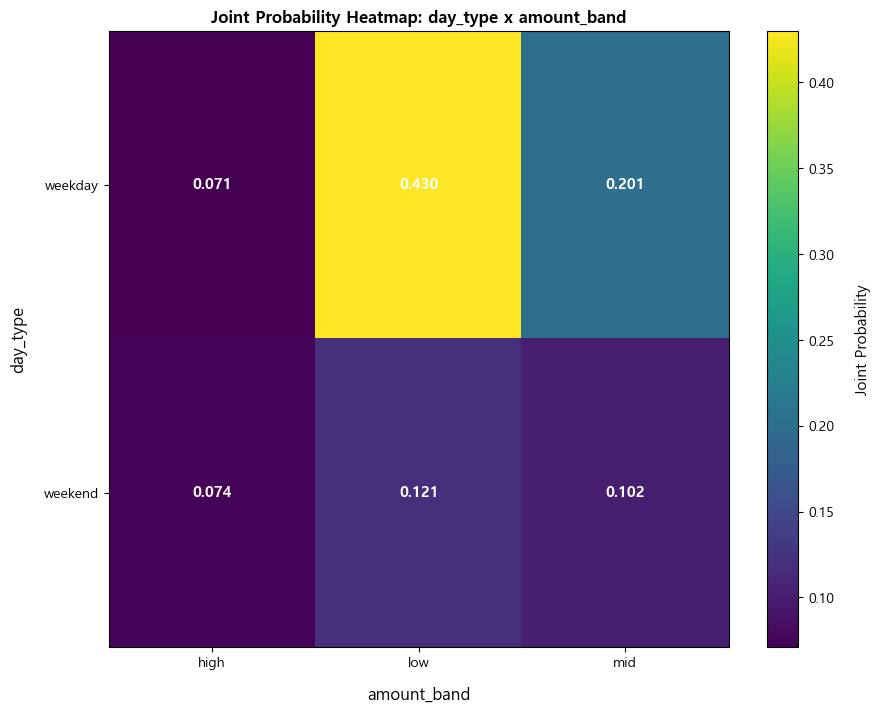

In [ ]:
prob = new_df.values
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111)

c = ax.pcolor(new_df)
ax.set_xticks(np.arange(prob.shape[1]) + 0.5, minor=False)
ax.set_yticks(np.arange(prob.shape[0]) + 0.5, minor=False)
ax.set_xticklabels(new_df.columns, minor=False)
ax.set_yticklabels(new_df.index, minor=False)
ax.invert_yaxis()
for i in range(prob.shape[0]):      # 행 (y 위치)
    for j in range(prob.shape[1]):  # 열 (x 위치)
        val = prob[i, j]
        color = "white"
        ax.text(
            j + 0.5, i + 0.5, f"{val:.3f}",
            ha="center", va="center", color=color, fontsize=11, fontweight="bold"
        )
cbar = fig.colorbar(c, ax=ax)
cbar.set_label('Joint Probability', fontsize=11, labelpad=15)
ax.set_title('Joint Probability Heatmap: day_type x amount_band',fontweight='bold')
ax.set_xlabel('amount_band', fontsize=12, labelpad=12)
ax.set_ylabel('day_type', fontsize=12, labelpad=12)
plt.show()

In [ ]:
def f_X(x)